# Results, uncertainty, and next experiments

All candidate settings and ensemble weights were selected on the development partition.
The following holdout comparison was produced after freezing those choices. Lower log
loss is better. Accuracy is secondary because the competition scores probabilities.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path.home()/'prj/llm_classification_finetuning']
REPO = next(p for p in candidates if (p/'src/arena').is_dir() and (p/'results/attempt_001').is_dir())
sys.path.insert(0, str(REPO / 'src'))
from arena.data import ROOT, CLASSES, TEXT_COLUMNS
RESULTS = REPO / 'results/attempt_001'
ARTIFACTS = ROOT / 'runs/attempt_001'
FIGURES = ROOT / 'reports/attempt_001'
FIGURES.mkdir(parents=True, exist_ok=True)
summary = json.loads((RESULTS / 'data_summary.json').read_text())
evaluation = json.loads((RESULTS / 'metrics.json').read_text()) if (RESULTS/'metrics.json').exists() else None
comparison = pd.read_json(RESULTS / 'comparison.json').sort_values('dev_log_loss') if (RESULTS/'comparison.json').exists() else None
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})


,model,dev_log_loss,holdout_log_loss,holdout_accuracy,holdout_balanced_accuracy,holdout_macro_f1,holdout_brier
0,calibrated_ensemble,1.00643,1.00194,0.49626,0.49044,0.48590,0.60040
1,offline_ensemble,1.01402,1.00956,0.49835,0.49276,0.48874,0.60535
2,qwen3_256__gbdt,1.01717,1.01392,0.48374,0.47824,0.47437,0.60819
3,hybrid__gbdt,1.02182,1.02097,0.48374,0.47768,0.47232,0.61280
4,tfidf_svd__gbdt,1.02263,1.01883,0.48443,0.47862,0.47393,0.61140
5,qwen3_256__neural,1.02586,1.01786,0.48008,0.47587,0.47410,0.61088
6,rnn__end_to_end,1.02781,1.02584,0.47295,0.46883,0.46698,0.61657
7,tfidf_svd__neural,1.02791,1.02388,0.48321,0.47800,0.47459,0.61486
8,rnn_long__end_to_end,1.02798,1.02383,0.47713,0.47236,0.46950,0.61493
9,rnn__gbdt,1.02945,1.03036,0.47278,0.46605,0.45865,0.61904


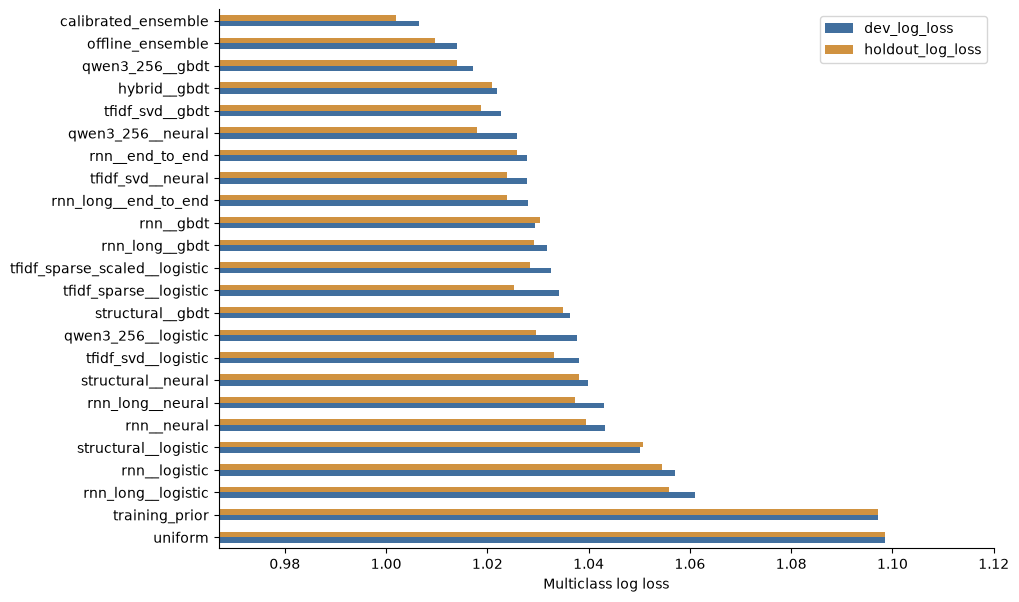

In [2]:
display(comparison.round(5))
plot = comparison[comparison.model != 'most_frequent_class'].sort_values('dev_log_loss', ascending=False)
ax = plot.plot.barh(x='model', y=['dev_log_loss','holdout_log_loss'], figsize=(10,7), color=['#416F9E','#D09240'])
ax.set(xlabel='Multiclass log loss', ylabel='', xlim=(max(0, plot[['dev_log_loss','holdout_log_loss']].min().min()-.035), 1.12))
plt.show()

## Constant majority baseline

The most-frequent-class model chooses the most frequent original training label and
always predicts it. It uses no development or holdout labels to choose the class.
Its accuracy, balanced accuracy, macro F1 and Brier score are included in the table.
The multiclass Brier score sums squared probability errors across all three classes
and ranges from 0 to 2.
Its hard one-hot probability output incurs a very large log loss on every other class;
sklearn clips zero probabilities at float64 machine epsilon. The separate training-prior
baseline predicts class-frequency probabilities and is a more useful log-loss reference.
The hard baseline intentionally keeps its constant original label without swap averaging.


In [3]:
display(comparison[comparison.model.isin(['most_frequent_class','training_prior'])].T)

,22,24
model,training_prior,most_frequent_class
dev_log_loss,1.097222,23.458474
holdout_log_loss,1.097218,23.460663
holdout_accuracy,0.349104,0.349104
holdout_balanced_accuracy,0.333333,0.333333
holdout_macro_f1,0.172512,0.172512
holdout_brier,0.665747,1.301792


## Frozen model choice and confirmation

Nonnegative ensemble weights and a shared probability temperature were fitted using
development predictions. The model choice below is determined by development log loss,
even if a different candidate happens to score best on holdout.
The confidence interval bootstraps prompt groups and compares the selected model's
holdout log loss with a training-prior baseline. Negative differences favor the model.


In [4]:
selection = evaluation['selection']
confirmation = evaluation['confirmation']
display(pd.Series({k:v for k,v in selection.items() if k not in ['weights','candidate_prediction_sha256']}))
display(pd.Series(selection['weights']).sort_values(ascending=False).rename('Ensemble weight'))
display(pd.Series(confirmation))

temperature                              0.877909
best_single_on_dev                qwen3_256__gbdt
selected_on_dev               calibrated_ensemble
fit_partition                                 dev
holdout_used_for_selection                  False
dtype: object

qwen3_256__gbdt                  3.019396e-01
hybrid__gbdt                     2.581930e-01
tfidf_sparse__logistic           2.317200e-01
qwen3_256__neural                1.365278e-01
tfidf_svd__neural                5.156843e-02
tfidf_sparse_scaled__logistic    1.871634e-02
rnn__end_to_end                  1.334871e-03
tfidf_svd__gbdt                  5.489814e-17
structural__logistic             2.404147e-17
rnn__logistic                    2.036109e-17
uniform                          1.587843e-17
rnn__gbdt                        9.564860e-18
rnn_long__end_to_end             3.944404e-18
rnn_long__logistic               2.754295e-18
qwen3_256__logistic              0.000000e+00
rnn_long__gbdt                   0.000000e+00
rnn__neural                      0.000000e+00
structural__gbdt                 0.000000e+00
rnn_long__neural                 0.000000e+00
structural__neural               0.000000e+00
tfidf_svd__logistic              0.000000e+00
Name: Ensemble weight, dtype: floa

selected_model                 calibrated_ensemble
holdout_log_loss                          1.001945
difference_vs_prior                      -0.095273
group_bootstrap_95pct_ci    [-0.108834, -0.082431]
n_holdout                                     5749
n_prompt_groups                               5187
bootstrap_replicates                          2000
dtype: object

## Error analysis and calibration

When the local artifact directory is available, examine the selected model's confusion
matrix and confidence calibration. These diagnostics describe the frozen experiment;
they must not be used to retune against this same holdout and claim fresh confirmation.


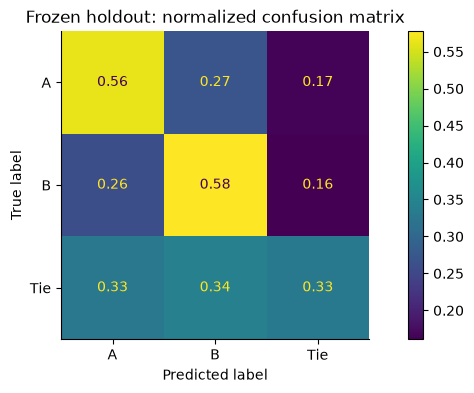

,mean_confidence,accuracy,count
bin,,,
"(0.3, 0.4]",0.375677,0.369707,1228
"(0.4, 0.5]",0.444438,0.443913,2300
"(0.5, 0.6]",0.543956,0.540630,1206
"(0.6, 0.7]",0.646379,0.672213,601
"(0.7, 0.8]",0.740557,0.725275,273
"(0.8, 0.9]",0.852979,0.869231,130
"(0.9, 1.0]",0.920878,1.000000,11


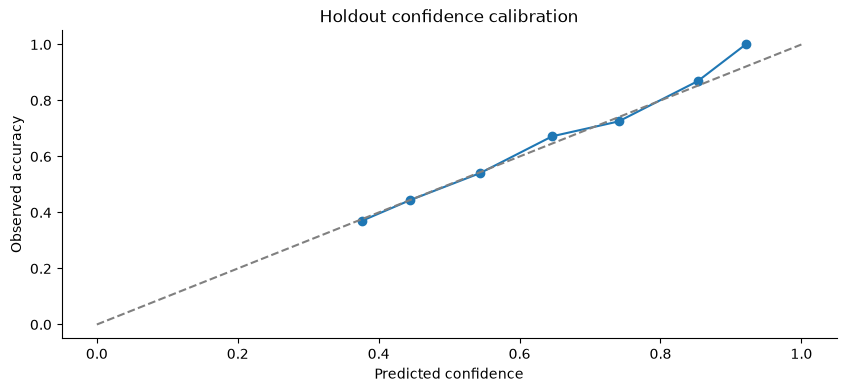

In [5]:
if (ARTIFACTS/'labels.npy').exists():
    from sklearn.metrics import ConfusionMatrixDisplay
    y = np.load(ARTIFACTS/'labels.npy')
    idx = np.load(ARTIFACTS/'holdout_idx.npy')
    name = selection['selected_on_dev']
    p = np.load(ARTIFACTS/f'{name}_predictions.npy')[idx]
    ConfusionMatrixDisplay.from_predictions(y[idx], p.argmax(1), display_labels=['A','B','Tie'], normalize='true', values_format='.2f')
    plt.title('Frozen holdout: normalized confusion matrix'); plt.show()
    confidence = p.max(1)
    correct = (p.argmax(1) == y[idx]).astype(float)
    bins = pd.cut(confidence, np.linspace(0,1,11), include_lowest=True)
    calibration = pd.DataFrame({'bin':bins,'confidence':confidence,'correct':correct}).groupby('bin', observed=True).agg(mean_confidence=('confidence','mean'), accuracy=('correct','mean'), count=('correct','size'))
    display(calibration)
    plt.plot(calibration.mean_confidence, calibration.accuracy, marker='o')
    plt.plot([0,1],[0,1], '--', color='grey')
    plt.xlabel('Predicted confidence'); plt.ylabel('Observed accuracy'); plt.title('Holdout confidence calibration'); plt.show()
else:
    print('Detailed prediction artifacts remain under ~/database; committed aggregate results are displayed above.')

## Further approaches

1. **Cross-encoder preference model:** jointly encode the question and both answers to
   learn factual and instruction-following interactions that separate embeddings miss.
2. **Preference-tuned LLM:** train a LoRA adapter with a three-class head, enough context
   for all turns, response swapping, and optional teacher distillation. This needs a GPU.
3. **Pairwise utility with a tie head:** use a shared response scorer, an antisymmetric
   A/B score difference, and a separate tie model. This builds the task's symmetry into
   the architecture.
4. **Better recurrent representation:** test subword tokenization, more context,
   pretrained token vectors, stronger regularization and cross-fitted features before
   deciding whether recurrent embeddings add enough value for their cost.
5. **Multi-fold confirmation:** estimate variance across prompt-grouped folds and seeds;
   compare semantic dimension and context limits within nested validation.

The structural baseline, combined representation, and calibrated ensemble are the
additional approaches actually tested in this attempt. The ideas above are proposals.


In [6]:
for limitation in evaluation['limitations']: print('•', limitation)

• One fixed prompt-grouped split; no repeated-seed or full cross-validation evidence.
• Visible test has three examples; submission CSV is a format check, not a leaderboard score.
• The original sparse TF-IDF logistic fit reached its 250-iteration cap; the separately scaled follow-up converged in 79 iterations.
• Qwen features require an external service and are unsuitable for internet-disabled Kaggle inference without a local model.
• The from-scratch GRU has limited context and cannot be assumed to match pretrained language-model quality.


## Submission status

`submission_preview.csv` under the artifact directory covers the three visible examples
and validates file shape only. The separate offline Kaggle notebook trains deployable
local models and produces `submission.csv` for whichever test set Kaggle provides.
A leaderboard score is evidence only after Kaggle has rerun and scored that notebook.


In [7]:
kaggle_status = RESULTS/'kaggle_submission.json'
if kaggle_status.exists():
    display(pd.Series(json.loads(kaggle_status.read_text()), name='Recorded Kaggle submission'))

url              /code/arseniytrushin/llm-preference-offline-at...
status                                   SubmissionStatus.COMPLETE
ref                                                       57866428
public_score                                               1.00897
private_score                                                     
description      Attempt 001: offline TF-IDF, GRU and structura...
date                                    2026-11-01 08:55:33.660000
Name: Recorded Kaggle submission, dtype: object